In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
import joblib
import warnings

warnings.filterwarnings('ignore')
%matplotlib inline

In [3]:
# Load the dataset
try:
    data = pd.read_excel("Data_Train.xlsx")
    print("✅ Dataset loaded successfully.")
except FileNotFoundError:
    print("❌ ERROR: 'Data_Train.xlsx' not found.")

data.dropna(inplace=True)

# Convert Date_of_Journey to datetime
data['Date_of_Journey'] = pd.to_datetime(data['Date_of_Journey'], dayfirst=True)

# Sort by date (Critical for Time Series)
data = data.sort_values('Date_of_Journey')

print(f"Date Range: {data['Date_of_Journey'].min()} to {data['Date_of_Journey'].max()}")

✅ Dataset loaded successfully.
Date Range: 2019-03-01 00:00:00 to 2019-06-27 00:00:00


In [4]:
data.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
537,SpiceJet,2019-03-01,Chennai,Kolkata,MAA → CCU,09:30,12:05,2h 35m,non-stop,No info,7298
8897,Air India,2019-03-01,Banglore,New Delhi,BLR → CCU → GAU → DEL,11:05,22:10,11h 5m,2 stops,Change airports,13576
7461,Vistara,2019-03-01,Banglore,New Delhi,BLR → AMD → DEL,06:40,10:25 02 Mar,27h 45m,1 stop,No info,12371
4507,IndiGo,2019-03-01,Kolkata,Banglore,CCU → BLR,20:25,23:05,2h 40m,non-stop,No info,4778
3853,Air India,2019-03-01,Banglore,New Delhi,BLR → BBI → DEL,09:30,23:45,14h 15m,1 stop,No info,12704


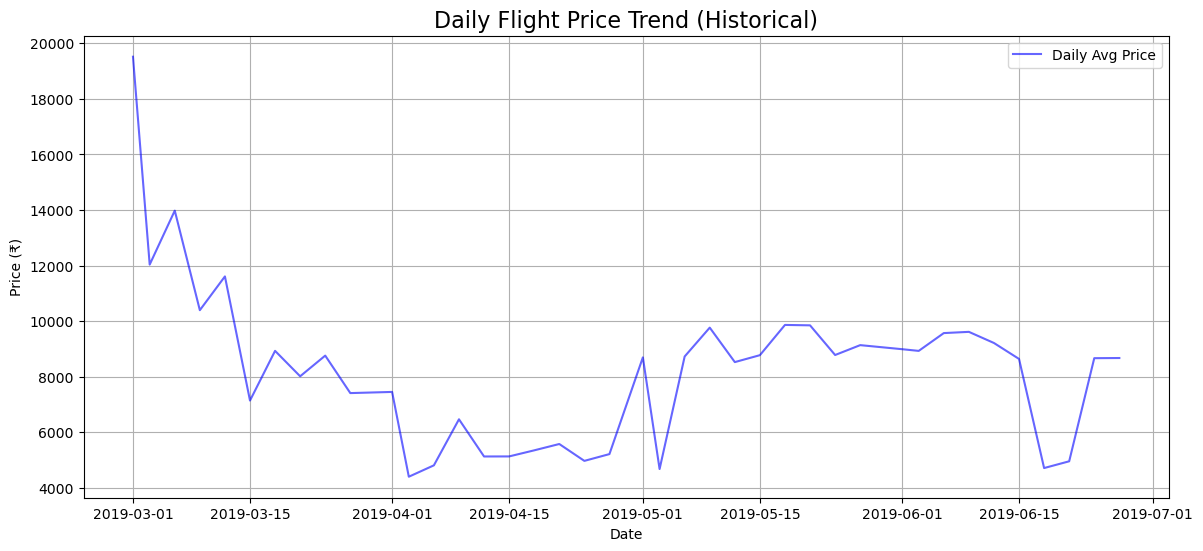

In [5]:
# Aggregate daily average price
daily_price = data.groupby('Date_of_Journey')['Price'].mean()

plt.figure(figsize=(14, 6))
plt.plot(daily_price.index, daily_price.values, label='Daily Avg Price', color='blue', alpha=0.6)
plt.title('Daily Flight Price Trend (Historical)', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Price (₹)')
plt.legend()
plt.grid(True)
plt.show()

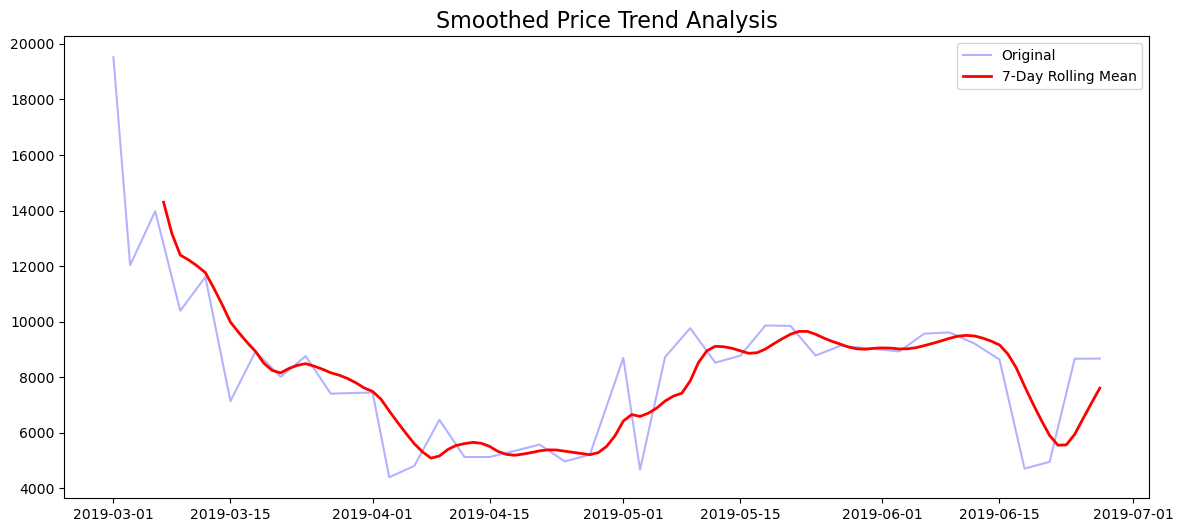

In [6]:
# Resample to ensure strictly daily frequency (fill missing days)
ts_data = daily_price.asfreq('D')
ts_data = ts_data.interpolate(method='linear')

# Visualizing Rolling Mean (Smoothing)
rolling_mean = ts_data.rolling(window=7).mean()

plt.figure(figsize=(14, 6))
plt.plot(ts_data, label='Original', color='blue', alpha=0.3)
plt.plot(rolling_mean, label='7-Day Rolling Mean', color='red', linewidth=2)
plt.title('Smoothed Price Trend Analysis', fontsize=16)
plt.legend()
plt.show()

In [7]:
print("Training ARIMA Model...")

# Order (p,d,q) = (5,1,0) is a standard starting point for daily data
# p=5 (Lag of 5 days), d=1 (Differencing once for stationarity), q=0
model = ARIMA(ts_data, order=(5,1,0))
model_fit = model.fit()

print(model_fit.summary())

Training ARIMA Model...
                               SARIMAX Results                                
Dep. Variable:                  Price   No. Observations:                  119
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -945.745
Date:                Thu, 18 Dec 2025   AIC                           1903.491
Time:                        18:16:13   BIC                           1920.115
Sample:                    03-01-2019   HQIC                          1910.241
                         - 06-27-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2100      0.070      2.993      0.003       0.072       0.348
ar.L2         -0.3839      0.085     -4.540      0.000      -0.550      -0.218
ar.L3          0.0506      0

In [8]:
# Get the fitted values (The "Trend" the model learned)
arima_trend = model_fit.fittedvalues.reset_index()
arima_trend.columns = ['Date', 'ARIMA_Price']

# Save this specific trend data to a pickle file
# We save it separately so it doesn't interfere with your Random Forest files
joblib.dump(arima_trend, 'time_series_data.pkl')

print("✅ SUCCESS: 'time_series_data.pkl' saved successfully.")

✅ SUCCESS: 'time_series_data.pkl' saved successfully.
